# Assignment 1: Predicting and Classifying Highway Traffic Volume

In this assignment you'll build two models on a real dataset of hourly highway traffic: a linear regression that predicts the actual traffic volume, and a logistic regression that predicts whether the coming hour counts as "heavy traffic." You'll implement each one three different ways: scikit-learn (as a sanity check), the normal equation (regression only, closed-form), and batch gradient descent from scratch. That way you can see how the three relate and where they agree. Along the way you'll also do real data cleaning and feature engineering, since the dataset is given to you exactly as collected, not pre-cleaned for you.

### The dataset

Metro Interstate Traffic Volume: hourly westbound traffic on I-94 between Minneapolis and St. Paul, 2012-2018 (48,204 hourly observations). Each row has a timestamp, weather conditions (temperature, rainfall, snowfall, cloud cover, a text description), whether the day was a US holiday, and the traffic volume for that hour. `metro_traffic.csv` is the raw sensor/weather-station export, so expect a few quirks in it.

### Your two prediction tasks

1. **Regression:** predict `traffic_volume`.
2. **Classification:** predict whether the coming hour is a heavy-traffic hour (the top 25% of `traffic_volume`).

### Organization

Five parts, all required:

- **Part 0** — loading, cleaning, and the train/test split.
- **Part A** — linear regression: standardization, the normal equation, batch gradient descent.
- **Part B** — logistic regression: sigmoid, cross-entropy, batch gradient descent, thresholds and class imbalance.
- **Part C** — preprocessing and feature engineering: turn the raw columns into a feature set worth modelling.
- **Part D** — regularization on top of your Part C features, and how to decide whether you actually need it.

Parts C and D build directly on the features you construct yourself, so do them in order.

Don't rename variables that are already provided; later cells depend on them. Cells marked `# --- GIVEN, just run this cell ---` are fine to run as-is, no changes needed.


## Part 0 — Data Loading, Cleaning & Train/Test Split


In [58]:
# --- GIVEN, just run this cell ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

%matplotlib inline
np.random.seed(42)


In [59]:
# --- GIVEN, just run this cell ---
df = pd.read_csv('metro_traffic.csv')
print(df.shape)
display(df.head())
df.describe(include='all').T


(48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
holiday,61,11,Labor Day,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp,48204.0,NaN,NaN,NaN,281.20587,13.338232,0.0,272.16,282.45,291.806,310.07
rain_1h,48204.0,NaN,NaN,NaN,0.334264,44.789133,0.0,0.0,0.0,0.0,9831.3
snow_1h,48204.0,NaN,NaN,NaN,0.000222,0.008168,0.0,0.0,0.0,0.0,0.51
clouds_all,48204.0,NaN,NaN,NaN,49.362231,39.01575,0.0,1.0,64.0,90.0,100.0
weather_main,48204,11,Clouds,15164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_description,48204,38,sky is clear,11665,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_time,48204,40575,2013-04-18 22:00:00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
traffic_volume,48204.0,NaN,NaN,NaN,3259.818355,1986.86067,0.0,1193.0,3380.0,4933.0,7280.0


### 0.1 Look closely at the summary above

Two things to check before you model anything:

- Does every column's min/max make physical sense? (`temp` is Kelvin; `rain_1h` is mm of rain in the last hour.) A couple of readings here are not just unusual, they are physically impossible, and a sensor that reports an impossible value is reporting an error rather than a measurement. You'll drop those below. Left in, standardization treats them as genuine extreme values, and a handful of rows then carries enough leverage to distort the fit in Part A.
- Is `holiday` mostly missing, or is something else going on? Leave this one alone for now; it's a subtler problem and you'll handle it in Part C.

Now look at duplicates:


In [60]:
# --- GIVEN, just run this cell ---
print('Rows that share a date_time with another row:', df.duplicated(subset=['date_time'], keep=False).sum())
df[df.duplicated(subset=['date_time'], keep=False)].sort_values('date_time').head(4)


Rows that share a date_time with another row: 13074


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,NaN,281.25,0.0,0.0,99,Rain,light rain,2012-10-10 07:00:00,6793
179,NaN,281.25,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793
180,NaN,280.10,0.0,0.0,99,Rain,light rain,2012-10-10 08:00:00,6283
181,NaN,280.10,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283


Some hours appear more than once with the *same* `traffic_volume` but a *different* weather report (the station logged more than one condition for that hour). If you split into train/test before removing these, the same hour could land on both sides, which is a case of data leakage.

**Your task, in one cell:**
1. Remove duplicate timestamps (keep one row per `date_time`), convert `date_time` to a real datetime, and sort chronologically. Store back into `df`.
2. Drop the rows with physically impossible readings: a `temp` of exactly 0 (that's 0 Kelvin, i.e. absolute zero) and the single `rain_1h` reading in the thousands of millimetres. Between them that's about a dozen rows out of 40,000.
3. Split `df` into `train`/`test` (80/20, `random_state=42`).

Dropping rows *before* the split is fine here, and is not leakage: you're not using the test set or the target to make the decision, you're applying a physical fact (temperatures aren't 0 K, an hour doesn't get ten metres of rain) that you'd know before seeing any data at all.

*Hint: `drop_duplicates`, `pd.to_datetime`, `train_test_split`.*


In [61]:
# TODO: 1) dedupe by date_time (keep='first'), convert date_time to datetime, sort chronologically
#       2) drop the physically impossible rows (temp == 0, and the absurd rain_1h reading)
#       3) split into train/test (80/20, random_state=42)

''' write your code here '''
df = df.drop_duplicates(subset=['date_time'], keep="first")
df['date_time'] = pd.to_datetime(df['date_time'])
df = df.sort_values('date_time')
df = df[df['rain_1h'] < 1000]
df = df[df['temp']!=0]
train, test = train_test_split(df, test_size=0.2, random_state=42)

print(df.shape, train.shape, test.shape)
assert df['date_time'].duplicated().sum() == 0
assert (df['temp'] == 0).sum() == 0 and df['rain_1h'].max() < 1000


(40564, 9) (32451, 9) (8113, 9)


### 0.2 Defining the classification target: `heavy_traffic`

"Heavy traffic" = top 25% of `traffic_volume`. The threshold must come from **training data only** (else test-set information leaks into the label itself).


In [62]:
# --- GIVEN, just run this cell ---
heavy_threshold = train['traffic_volume'].quantile(0.75)
print(f'Heavy-traffic threshold: {heavy_threshold:.1f} vehicles/hour')

train = train.copy()
test = test.copy()
train['heavy_traffic'] = (train['traffic_volume'] >= heavy_threshold).astype(int)
test['heavy_traffic']  = (test['traffic_volume']  >= heavy_threshold).astype(int)
print(train['heavy_traffic'].value_counts(normalize=True))


Heavy-traffic threshold: 4944.0 vehicles/hour
heavy_traffic
0    0.749746
1    0.250254
Name: proportion, dtype: float64


## Part A — Linear Regression: Predicting `traffic_volume`

Use a small, numeric feature set here on purpose: `temp`, `rain_1h`, `snow_1h`, `clouds_all`. The point of Part A is getting the normal equation and gradient descent right, not finding the best possible feature set (that comes later, in Part C).


### A.1 Feature standardization

$$x_i^{scaled} = \frac{x_i - \mu}{\sigma}$$

Compute $\mu,\sigma$ from **train only**; apply the same values to test.


In [63]:
FEATURES_A = ['temp', 'rain_1h', 'snow_1h', 'clouds_all']
TARGET_A = 'traffic_volume'

def standardize(X, mu=None, sigma=None):
    # If mu/sigma are None, compute them from X (training set). Otherwise just apply them (test set).
    ####  PUT YOUR CODE HERE   #####
    mu = mu if mu is not None else np.mean(X, axis=0)
    sigma = sigma if sigma is not None else np.std(X, axis=0)
    X_scaled = (X - mu)/sigma
    #################################
    return X_scaled, mu, sigma

X_train_raw = train[FEATURES_A].values.astype(float)
X_test_raw  = test[FEATURES_A].values.astype(float)
y_train = train[TARGET_A].values.reshape(-1, 1).astype(float)
y_test  = test[TARGET_A].values.reshape(-1, 1).astype(float)

X_train_scaled, mu, sigma = standardize(X_train_raw)
X_test_scaled, _, _ = standardize(X_test_raw, mu, sigma)
print('train mean per feature:', X_train_scaled.mean(axis=0))
print('train std  per feature:', X_train_scaled.std(axis=0))


train mean per feature: [ 6.45709078e-16  1.40133540e-17 -6.13084238e-18 -1.35535408e-16]
train std  per feature: [1. 1. 1. 1.]


### A.2 The Normal Equation & Cost Function

$$J(w,b) = \frac{1}{2m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)^2
\qquad\text{where}\qquad f_{w,b}(x) = w_1x_1 + \cdots + w_nx_n + b$$

Gradient descent (A.3) finds $w$ and $b$ by stepping downhill. Linear regression also has a **closed form** that lands on the exact minimum in one shot, the normal equation:

$$\begin{bmatrix} b \\ w \end{bmatrix} = (\tilde{X}^T\tilde{X})^{-1}\tilde{X}^Ty
\qquad\text{where}\qquad \tilde{X} = \begin{bmatrix} 1 & x_1 & \cdots & x_n \\ \vdots & & & \vdots \end{bmatrix}$$

The leading column of ones is what the intercept multiplies, so the solution comes back as one stacked vector. (The lectures write that stacked vector as $\theta$; this assignment stays in $w$ and $b$ throughout, so we split it apart again on the way out.) Build $\tilde{X}$ inside the function, solve, then return `w` and `b` separately.

**On the inverse.** $(\tilde{X}^T\tilde{X})^{-1}$ exists only when the columns of $\tilde{X}$ are linearly independent. When they are not, the matrix is singular and `np.linalg.inv` either fails or returns numerical garbage. The standard replacement is the **Moore-Penrose pseudoinverse**, `np.linalg.pinv`, which returns a sensible answer either way: when the inverse exists it gives the same result, and when it doesn't it picks the smallest-norm solution out of the infinitely many that fit equally well. (`np.linalg.lstsq` does the same job.) Use `inv` here so you see the textbook form. You will meet a matrix in Part C where the difference matters.

The cost function is given below; you implement the normal equation.


In [64]:
def compute_cost(X, y, w, b):
    # --- GIVEN ---
    m = y.shape[0]
    f = X.dot(w) + b
    return (1 / (2 * m)) * np.sum((f - y) ** 2)

def normal_equation(X, y):
    # Return w (a column vector, one entry per feature) and b (a single number).
    ####  PUT YOUR CODE HERE: build X_aug by prepending a column of ones, solve for the
    ####  stacked parameter vector, then split it into b and w.
    X_aug = np.hstack([np.ones((X.shape[0], 1)), X])
    params = np.linalg.inv(X_aug.T@X_aug)@X_aug.T@y
    b = params[0]
    w = params[1:]

    #################################
    return w, b

w_ne, b_ne = normal_equation(X_train_scaled, y_train)
print('w (normal equation):', w_ne.ravel())
print('b (normal equation):', b_ne)
print('test cost:', compute_cost(X_test_scaled, y_test, w_ne, b_ne))


w (normal equation): [305.96472507 -54.02061829  -1.51604608 194.44444953]
b (normal equation): [3285.73446119]
test cost: 1920822.6059246117


### A.3 Batch Gradient Descent

The normal equation solves for $w$ and $b$ in one shot, but it needs to invert a matrix, which stops being practical once you have a lot of features. Gradient descent gets to the same place iteratively: start somewhere, compute the gradient of the cost over the **whole** training set, take a small step downhill, repeat.

These are the two update rules from lecture, with the $w$ one now done for all $n$ features at once:

$$\frac{\partial J}{\partial w} = \frac{1}{m}X^T\big(Xw + b - y\big)
\qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)$$

$$w := w - \alpha\frac{\partial J}{\partial w}
\qquad
b := b - \alpha\frac{\partial J}{\partial b}
\qquad\text{\small(simultaneously)}$$

The first gradient is a vector with one entry per feature, the second is a single number. **Simultaneously** matters: compute both gradients from the current $w$ and $b$ before you update either one.

Every `record_every` iterations we save the cost and the current parameters so you can watch training progress. You fill in the update.


In [65]:
def gradient_descent(X, y, w, b, alpha, num_iters, record_every=25):
    m = y.shape[0]
    cost_history, history, iters_recorded = [], [], []

    def func(w, b, X):
        Y =X@w+b
        return Y

    for i in range(num_iters):
        ####  PUT YOUR CODE HERE: compute the predictions f, then dw and db over the full
        ####  training set, then update w and b simultaneously.
        f = func(w, b, X)
        delJdelb = np.sum(f-y)/m
        delJdelw = (X.T@(f-y))/m
        w = w-(alpha*delJdelw)
        b = b-(alpha*delJdelb)

        #####################################################################################

        if i % record_every == 0 or i == num_iters - 1:
            cost_history.append(compute_cost(X, y, w, b))
            history.append((w.copy(), b))
            iters_recorded.append(i)

    return w, b, cost_history, history, iters_recorded

w_init = np.zeros((X_train_scaled.shape[1], 1))
b_init = 0.0
w_gd, b_gd, cost_history, history, iters_recorded = gradient_descent(
    X_train_scaled, y_train, w_init, b_init, alpha=0.01, num_iters=500)
print('w (batch gradient descent):', w_gd.ravel())
print('w (normal equation):       ', w_ne.ravel())
print()
print('b (batch gradient descent):', b_gd)
print('b (normal equation):       ', b_ne)


w (batch gradient descent): [302.49804351 -52.18075895  -1.46700842 191.3543771 ]
w (normal equation):        [305.96472507 -54.02061829  -1.51604608 194.44444953]

b (batch gradient descent): 3264.145598628526
b (normal equation):        [3285.73446119]


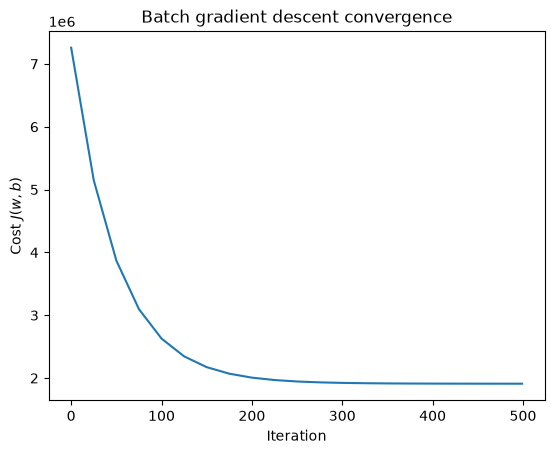

,b,temp,rain_1h,snow_1h,clouds_all
iteration,,,,,
0,32.857345,2.812891,-0.228964,-0.017453,1.568583
25,755.577160,65.213886,-6.024597,-0.382103,36.987144
50,1317.724070,114.614764,-11.740900,-0.639274,65.994103
75,1754.973943,153.758284,-17.157025,-0.822872,89.725764
100,2095.076234,184.800998,-22.148539,-0.956143,109.123535
125,2359.615061,209.440173,-26.656541,-1.054933,124.965600
150,2565.379010,229.012887,-30.665543,-1.129981,137.893925
175,2725.426605,244.573463,-34.187785,-1.188532,148.437160
200,2849.915043,256.954045,-37.252248,-1.235446,157.029951


In [66]:
# --- GIVEN, just run this cell ---
plt.plot(iters_recorded, cost_history)
plt.xlabel('Iteration'); plt.ylabel(r'Cost $J(w,b)$'); plt.title('Batch gradient descent convergence')
plt.show()

pd.DataFrame([np.r_[b_snap, w_snap.ravel()] for w_snap, b_snap in history],
             columns=['b'] + FEATURES_A, index=pd.Index(iters_recorded, name='iteration'))


### A.4 Watch the Hypothesis Learn

The table above shows how the *coefficients* moved iteration by iteration. Now look at what that means for the *model itself*: plot predicted vs. actual `traffic_volume` on the test set using a few of the $(w, b)$ snapshots in `history`, from early training to the end.

Look at the last panel carefully once you have it. How close do the predictions come to the diagonal, and how wide is the range of values the model predicts compared with the range of actual traffic volumes? Hold on to what you see; you will be asked about it in A.5, and Part C will change it.


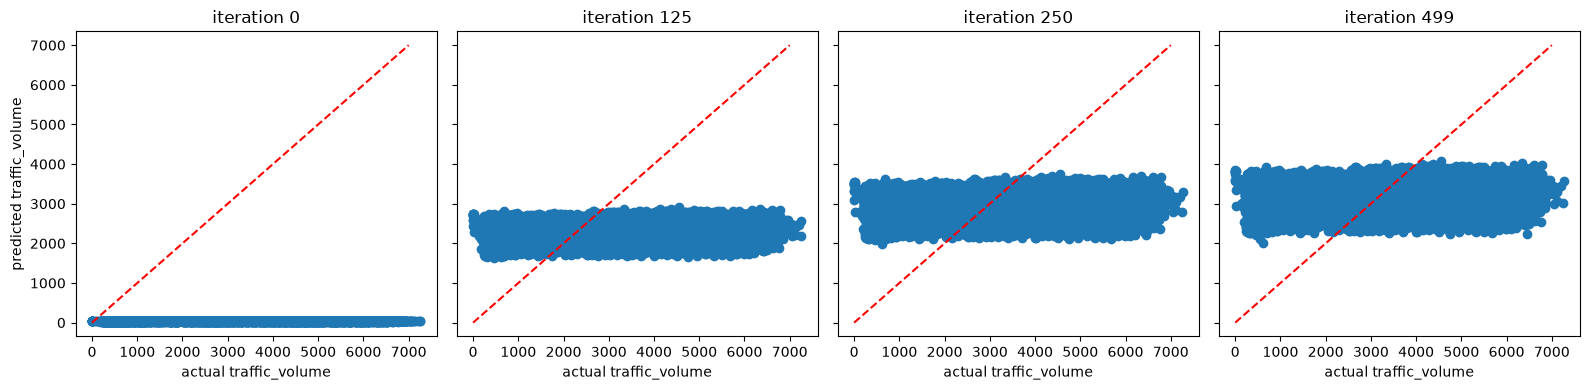

In [67]:
# TODO: for a handful of the recorded iterations (e.g. the first, one or two from partway through,
# and the last), unpack that iteration's (w, b) from history, predict on X_test_scaled, and make a
# scatter plot of predicted vs. actual traffic_volume (one panel per snapshot). A diagonal reference
# line (perfect predictions) makes it easy to see the fit improving.

snapshot_idxs = [0, len(history) // 4, len(history) // 2, -1]  # feel free to pick others
fig, axes = plt.subplots(1, len(snapshot_idxs), figsize=(4 * len(snapshot_idxs), 4), sharey=True)

for ax, idx in zip(axes, snapshot_idxs):
    ####  PUT YOUR CODE HERE: w_snap, b_snap = history[idx]; predict on X_test_scaled; scatter vs. y_test   #####
    w_snap, b_snap = history[idx]
    y_pred = X_test_scaled @ w_snap + b_snap
    ax.scatter(y_test, y_pred)
    ax.plot([0, 7000], [0, 7000], 'r--')

    #################################################################################################
    ax.set_title(f'iteration {iters_recorded[idx]}')
    ax.set_xlabel('actual traffic_volume')

axes[0].set_ylabel('predicted traffic_volume')
plt.tight_layout()
plt.show()


In [68]:
# --- GIVEN, sanity-check against scikit-learn, just run this cell ---
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lin_reg = LinearRegression().fit(X_train_scaled, y_train)
y_pred_sklearn = lin_reg.predict(X_test_scaled)

print('sklearn intercept, coef:', lin_reg.intercept_, lin_reg.coef_)
print('sklearn test MSE:        ', mean_squared_error(y_test, y_pred_sklearn), ' R2:', r2_score(y_test, y_pred_sklearn))
print('your normal-eq test MSE: ', 2 * compute_cost(X_test_scaled, y_test, w_ne, b_ne))
print('your batch GD test MSE:  ', 2 * compute_cost(X_test_scaled, y_test, w_gd, b_gd))


sklearn intercept, coef: [3285.73446119] [[305.96472507 -54.02061829  -1.51604608 194.44444953]]
sklearn test MSE:         3841645.2118492224  R2: 0.025433051636335025
your normal-eq test MSE:  3841645.2118492234
your batch GD test MSE:   3843072.3178877397


### A.5 Reflection — answer directly in this cell

Run the two cells below first, then answer:

1. Re-running gradient descent on the **unstandardized** raw features (same `alpha=0.01`), what happens to the cost, and why?

  *Your answer:* The cost grows larger and larger instead of becoming smaller as we iterate. Since the data is unstandardized, features have different scales betwen each other. Given that our features have completely different scales (Rain and snow usually less than 1, temp usually around 300) the gradient would over shoot at each iteration and we would start getting away from the min, and cost will start increasing.

2. In A.4 you were asked to look at the spread of the final panel's predictions. Report what you saw, and say what it implies about how much these four weather features actually explain. Is that a problem with your implementation?

  *Your answer:* The spread in y_test ranges from 0 to 7000, while that of y_pred ranges from 2000-4000. A completely useless feature would predict the mean of it in place of the param. The range of y_pred is around the mean, not exactly equal to the mean, but close to it. Which means that these features are not totally useless but arent really helpful. No it is not a problem with my implementation, since the function (at large n) gave values of the params close to that of sklearn and closed form.

3. Compare the parameters from the three routes — your normal equation, your gradient descent, and scikit-learn. Which of them agree, which don't, and by how much? Is any disagreement a bug or is it expected? The second cell below reruns gradient descent at `alpha=0.1`; report what changes and explain what it tells you about the learning rate, the iteration count, and how gradient descent approaches the minimum.

  *Your answer:* The normal equation and that of sklearn agree exactly, while the one found by gradient descent is slightly different to either of them. It is different by  around 21.5, 3.5, 2, 0.1, and 3 for b, w1, w2, w3, w4 respectively. This disagreement is expected, we need to tune the hyper parameters around and experiment with them to increase the accuracy for our model. At learning rate alpha = 0.1, the model converged to a result much closer to the result found by the closed form function. This bigger alpha allowed the weights to take bigger jumps as the value of the cost function moves closer and closer to the minimum. It is not always the case that a bigger alpha helps us, but here in this instance it did.

In [69]:
# Use this cell for question A.5.1 — rerun gradient_descent on X_train_raw, the UNSTANDARDIZED
# features, at the same alpha=0.01. Use num_iters=50, record_every=10.

''' write your code here '''
w_gd_un, b_gd_un, cost_history_un, history_un, iters_recorded_un = gradient_descent(
    X_train_raw, y_train, w_init, b_init, alpha=0.01, num_iters=50, record_every=10)
print(cost_history_un)

[np.float64(3586498711520.221), np.float64(5.578041978439602e+70), np.float64(8.675474041270197e+128), np.float64(1.349287978320436e+187), np.float64(2.0985343737752718e+245), np.float64(4.9493296392615694e+297)]


In [70]:
# --- GIVEN, for question A.5.2, just run this cell ---
w_fast, b_fast, _, _, _ = gradient_descent(
    X_train_scaled, y_train, np.zeros((X_train_scaled.shape[1], 1)), 0.0, alpha=0.1, num_iters=500)

def gap_to_normal_eq(w, b):
    return max(np.abs(w - w_ne).max(), abs(b - b_ne))

print('alpha=0.01, 500 iters -> largest gap to the normal equation:', gap_to_normal_eq(w_gd, b_gd))
print('alpha=0.1,  500 iters -> largest gap to the normal equation:', gap_to_normal_eq(w_fast, b_fast))


alpha=0.01, 500 iters -> largest gap to the normal equation: [21.58886256]
alpha=0.1,  500 iters -> largest gap to the normal equation: [1.36424205e-12]


## Part B — Logistic Regression: Classifying `heavy_traffic`

Reuse the standardized features from Part A, now predicting `heavy_traffic`.


### B.1 Sigmoid & Cross-Entropy Cost

Same parameters as Part A, $w$ and $b$, and the same linear combination $z = w_1x_1 + \cdots + w_nx_n + b$. The only new step is squashing $z$ through the sigmoid so the output can be read as a probability:

$$f_{w,b}(x) = g(z) = \frac{1}{1+e^{-z}}$$

$$J(w,b) = -\frac{1}{m}\sum_{i=1}^m \Big[y^{(i)}\log f_{w,b}(x^{(i)}) + (1-y^{(i)})\log\big(1-f_{w,b}(x^{(i)})\big)\Big]$$

(The logistic regression lecture writes these parameters as $\theta$, with $\theta_0$ for the intercept. Same quantities, different letter; we stay in $w$ and $b$ so the whole assignment reads the same way.)

The cost is given; you implement `sigmoid`.


In [71]:
y_train_cls = train['heavy_traffic'].values.reshape(-1, 1)
y_test_cls  = test['heavy_traffic'].values.reshape(-1, 1)
def sigmoid(z):
    ####  PUT YOUR CODE HERE   #####
    return 1 / (1+np.exp(-1*z))
    #################################

def compute_cost_logistic(X, y, w, b):
    # --- GIVEN ---
    m = y.shape[0]
    f = sigmoid(X.dot(w) + b)
    eps = 1e-12
    return -(1 / m) * np.sum(y * np.log(f + eps) + (1 - y) * np.log(1 - f + eps))


### B.2 Batch Gradient Descent for Logistic Regression

Same loop as A.3, but $f_{w,b}$ is now the sigmoid and the cost is cross-entropy:

$$\frac{\partial J}{\partial w} = \frac{1}{m}X^T\big(f_{w,b}(X) - y\big)
\qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)$$

Put these side by side with the two in A.3 before you write anything. There is no closed-form normal equation for logistic regression, so gradient descent is not a convenience here, it is the only option.


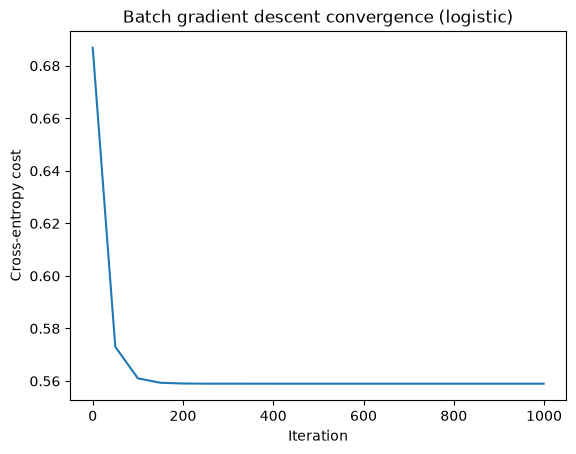

In [72]:
def gradient_descent_logistic(X, y, w, b, alpha, num_iters, record_every=50):
    m = y.shape[0]
    cost_history, iters_recorded = [], []

    for i in range(num_iters):
        ####  PUT YOUR CODE HERE: compute the predictions f, then dw and db over the full
        ####  training set, then update w and b simultaneously.
        delJdelw = (X.T@(sigmoid(X@w+b)-y))/m
        delJdelb = (np.sum(sigmoid(X@w+b)-y))/m
        w = w - alpha*delJdelw
        b = b - alpha*delJdelb
        
        #####################################################################################

        if i % record_every == 0 or i == num_iters - 1:
            cost_history.append(compute_cost_logistic(X, y, w, b))
            iters_recorded.append(i)

    return w, b, cost_history, iters_recorded

w_log, b_log, cost_history_log, iters_recorded_log = gradient_descent_logistic(
    X_train_scaled, y_train_cls, np.zeros((X_train_scaled.shape[1], 1)), 0.0,
    alpha=0.1, num_iters=1000)

plt.plot(iters_recorded_log, cost_history_log)
plt.xlabel('Iteration'); plt.ylabel('Cross-entropy cost'); plt.title('Batch gradient descent convergence (logistic)')
plt.show()


### B.3 Evaluating at the default threshold (0.5)


In [73]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, f1_score, classification_report

####  PUT YOUR CODE HERE: compute y_proba_test = sigmoid(X_test_scaled.dot(w_log) + b_log), then
####  threshold at 0.5 to get y_pred_class. Both names are used below, so keep them.  #####
y_proba_test = sigmoid(X_test_scaled.dot(w_log) + b_log)
y_pred_class = (y_proba_test>=0.5).astype(int)

##############################################################################################################

print('Accuracy:', accuracy_score(y_test_cls, y_pred_class))
print('Confusion matrix:\n', confusion_matrix(y_test_cls, y_pred_class))
print(classification_report(y_test_cls, y_pred_class))


Accuracy: 0.7409096511771232
Confusion matrix:
 [[6011    0]
 [2102    0]]
              precision    recall  f1-score   support

           0       0.74      1.00      0.85      6011
           1       0.00      0.00      0.00      2102

    accuracy                           0.74      8113
   macro avg       0.37      0.50      0.43      8113
weighted avg       0.55      0.74      0.63      8113



/Users/hamza/AUB/Fifth-Semester/Machine Learning/Assignment 1/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hamza/AUB/Fifth-Semester/Machine Learning/Assignment 1/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hamza/AUB/Fifth-Semester/Machine Learning/Assignment 1/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples.

### B.4 Thresholds & Class Imbalance

Look at the F1 you just got at threshold 0.5, and at the class balance from Part 0.2, before reading on.

ROC-AUC summarizes ranking quality across *all* thresholds; F1 depends on the single threshold you pick. 0.5 is a default, not a law of nature, and `heavy_traffic` is not a 50/50 split, so there is no particular reason to expect it to be the right cut here.

The threshold is something you **choose**, which makes it a parameter, which means it has to be chosen on data the test set never sees. Sweep it on the training set, then measure the winner once on test. (Stricter still would be a validation slice held out of `train`, for the same reason you'll use cross-validation in Part D — but training-set selection is enough to make the point here.)


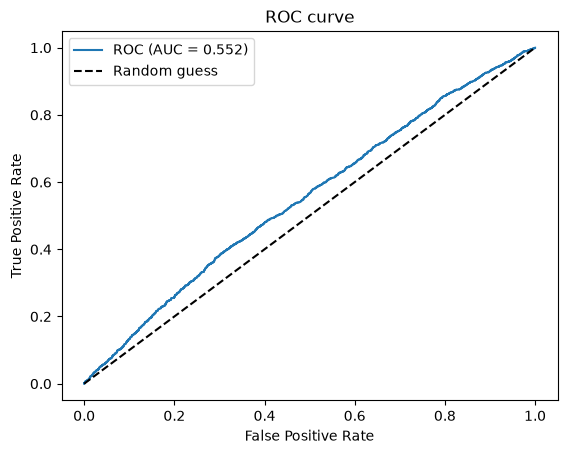

In [74]:
# --- GIVEN, just run this cell ---
from sklearn.metrics import roc_curve
y_proba_test = sigmoid(X_test_scaled.dot(w_log) + b_log)
fpr, tpr, _ = roc_curve(y_test_cls, y_proba_test)
auc = roc_auc_score(y_test_cls, y_proba_test)

plt.plot(fpr, tpr, label=f'ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC curve'); plt.legend()
plt.show()


In [75]:
from sklearn.linear_model import LogisticRegression

# TODO, two short parts:
# 1) For candidate_thresholds = np.linspace(0.05, 0.95, 19), compute F1 at each threshold on the
#    TRAINING set (you'll need y_proba_train from X_train_scaled the same way), pick the
#    threshold with the best training F1, and then report that threshold's F1 on the TEST set,
#    next to the test F1 at the default 0.5.
#    Choosing the threshold on training data and only then measuring on test is the point: the
#    threshold is a parameter like any other, and tuning it on the test set would be leakage.
# 2) Fit sklearn's LogisticRegression twice on X_train_scaled/y_train_cls: once plain, once with
#    class_weight='balanced'. For each, report the confusion matrix and F1 at threshold 0.5.
#    Keep the plain model and its predictions as clf_plain / pred_plain -- B.5 compares against them.

''' write your code here '''
candidate_thresholds = np.linspace(0.05, 0.95, 19)
y_proba_train = sigmoid(X_train_scaled.dot(w_log) + b_log)
y_train_class = (y_proba_train>=candidate_thresholds).astype(int)
f1_scores = np.array(list(map(lambda x: f1_score(y_train_cls, x), y_train_class.T)))
maxIndex = np.argmax(f1_scores)
print(f"F1 Score at 0.5: {f1_score(y_test_cls, y_pred_class)}")
print(f"F1 Score at max ({candidate_thresholds[maxIndex]}): {f1_score(y_test_cls, ((sigmoid(X_test_scaled.dot(w_log) + b_log))>=candidate_thresholds[maxIndex]).astype(int))}")
clf_plain = LogisticRegression().fit(X_train_scaled, y_train_cls.ravel())
clf_balanced = LogisticRegression(class_weight='balanced').fit(X_train_scaled, y_train_cls.ravel())
pred_plain = clf_plain.predict(X_test_scaled)
pred_balanced = clf_balanced.predict(X_test_scaled)

print('F1 Score Plain:', f1_score(y_test_cls, pred_plain))
print('F1 Score Balanced:', f1_score(y_test_cls, pred_balanced))
print('Confusion Matrix Plain:\n', confusion_matrix(y_test_cls, pred_plain))
print('Confusion Matrix Balanced:\n', confusion_matrix(y_test_cls, pred_balanced))

F1 Score at 0.5: 0.0
F1 Score at max (0.2): 0.413338997451147
F1 Score Plain: 0.0
F1 Score Balanced: 0.3816960799625176
Confusion Matrix Plain:
 [[6011    0]
 [2102    0]]
Confusion Matrix Balanced:
 [[2932 3079]
 [ 880 1222]]


### B.5 A Different Split: 25% vs. 35%

`heavy_traffic` was defined in Part 0.2 as the top 25% of `traffic_volume`. That 25% was a choice, not a fact about the data, and nothing stops you from drawing the line somewhere else. Here, redraw it at the top 35% and see what changes.

**Your task:**
1. Compute `heavy_threshold_35` as the 65th percentile of `train['traffic_volume']` (train only, same reasoning as Part 0.2).
2. Build `y_train_cls35` and `y_test_cls35` the same way `heavy_traffic` was built in Part 0.2, just with this new threshold.
3. Fit a plain `LogisticRegression` (no `class_weight`) on `X_train_scaled`/`y_train_cls35`.
4. Report its confusion matrix, accuracy, and F1 at threshold 0.5, and put them side by side with the plain (25%) `LogisticRegression` results from B.4.


In [76]:
# TODO: recompute the label at the 65th percentile and compare against the plain (25%)
# LogisticRegression results from B.4.

''' write your code here '''
heavy_threshold_35 = train['traffic_volume'].quantile(0.65)

train_35 = train.copy()
test_35 = test.copy()
train_35['heavy_traffic'] = (train['traffic_volume'] >= heavy_threshold_35).astype(int)
test_35['heavy_traffic']  = (test['traffic_volume']  >= heavy_threshold_35).astype(int)
y_train_cls35 = train_35["heavy_traffic"].values.reshape(-1, 1)
y_test_cls35  = test_35["heavy_traffic"].values.reshape(-1, 1)

clf_cls35 = LogisticRegression().fit(X_train_scaled, y_train_cls35.ravel())
pred_cls35 = clf_cls35.predict(X_test_scaled)

print('F1 Score Plain:', f1_score(y_test_cls, pred_plain))
print('F1 Score 35:', f1_score(y_test_cls35, pred_cls35))
print('Accuracy Plain:', accuracy_score(y_test_cls, pred_plain))
print('Accuracy 35:', accuracy_score(y_test_cls35, pred_cls35))
print('Confusion Matrix Plain:\n', confusion_matrix(y_test_cls, pred_plain))
print('Confusion Matrix 35:\n', confusion_matrix(y_test_cls35, pred_cls35))

F1 Score Plain: 0.0
F1 Score 35: 0.0
Accuracy Plain: 0.7409096511771232
Accuracy 35: 0.6442746209786762
Confusion Matrix Plain:
 [[6011    0]
 [2102    0]]
Confusion Matrix 35:
 [[5227    0]
 [2886    0]]


### B.6 Reflection — answer directly in this cell

1. Which threshold would you recommend for a real heavy-traffic classifier, and why? Would it change depending on how the prediction is used (a driver warning vs. long-term road planning)?

  *Your answer:* You cant recommend a threshold before knowing the use case, it depends. If a threshold is too high, we get more false negatives, and if it is too low, we get more false postives. For the driver warning use case, a high threshold (0.5) would be good as it is not catastrophic for the driver to get stuck in a 20 something min traffic jam. While for the long-term road planning, it is better to play it safe and evaluate the absolute worst case scenario, so a lower threshold is better (0.2 here is good). It is catastrophic for a road to have traffic jams always, for years or maybe decades.

2. In B.4, what changed between the plain model and the `class_weight='balanced'` one? Which kind of mistake (missed heavy-traffic hours, or false alarms) went up, and which went down, and why does reweighting the classes have that effect?

  *Your answer:* False positives significantly went up, while false negatives went down. Reweighting the classes increased the weight of the rarer class (the heavy traffic class). This makes missing a heavy traffic case more expensive, thus guiding the model toward weights that tend to not miss heavy traffic predictions as much, making the model predict more heavy traffic, making it predict more false positives.

3. In B.5, how did moving from a 25% to a 35% split change the class balance, and what happened to accuracy and to F1 as a result? Look at the two confusion matrices before you answer — did the model's actual behavior change at all between them? What does that tell you about using accuracy to compare models on problems with different class balances?

  *Your answer:* By moving down to 35%, we adjusted the class split into 35% Heavy Traffic, 65% not Heavy Traffic. And this reflected approximatly even into the testing set, by giving 36 Heavy by 64 not Heavy. Both models predicted at 50% threshold the normal case of not Heavy always. And this resulted into a 75% ish accuracy for the 25% split, and 65% ish accuracy for the 35% split. Meaning that it gave the number of the normal case values in the data set! Meaning that it changed nothing. A 0 F1 score for both models also support this idea. This means that accuracy is not always the best predictor of a model performance.


## Part C — Preprocessing & Feature Engineering

Parts A and B used four raw weather columns. The dataset also carries a timestamp, a day of week, a categorical weather description and a holiday flag, none of which you have touched. This part builds a feature set out of them and refits both models on it.

Keep the `train`/`test` split and the `heavy_traffic` threshold from Part 0. Every quantity you estimate here — a cutoff, a mean, an encoder vocabulary — must be computed on `train` and then applied to `test`.


### C.1 Two cleaning decisions

**Your task.** Make copies called `train_c` / `test_c` (so the Part A/B objects stay intact), then handle two columns and justify each in a one-line comment.

**1. `holiday`.** In 0.1 you saw it is almost entirely `NaN`. The obvious reading is "`NaN` means not a holiday". Before committing to it, check how many non-null values there are and **what hour of the day they fall on**, then decide what the column actually encodes and build a 0/1 `is_holiday` from it. Reconstruct it from `train` only.

**2. `rain_1h`.** The impossible reading is gone, but a long right tail of genuinely heavy hours remains. Leave it, cap it at a high training percentile, or log-transform it — all defensible. Part 0 was correcting an impossibility; this is a modelling judgement, so say which you picked and why.


In [77]:
# TODO: create train_c / test_c as copies, then:
#   1) work out what the holiday column is actually encoding and build a correct 0/1 'is_holiday'
#   2) decide what to do about the rain_1h tail, and do it (fit any cutoff on train only)
# Justify both in a one-line comment each.

''' write your code here '''
train_c = train.copy()
test_c = test.copy()

# A holiday is only labeled on its midnight row, so we spread each labeled date to the whole day, using dates from train only.
holiday_days_train = train_c["date_time"][train_c["holiday"].notna()]
holiday_dates = holiday_days_train.dt.normalize().unique()
train_c["is_holiday"] = train_c["date_time"].dt.normalize().isin(holiday_dates).astype(int)
test_c["is_holiday"]  = test_c["date_time"].dt.normalize().isin(holiday_dates).astype(int)

# By leaving as is, extreme values really affect linear and logistic regression. By capping we lose slight differences after we cross the gap, while also information about strong storms. By loging we gurantee that none of the data is thrown away, including the extreme storms. 
# We do need to transform the data, given the models, as such log1p is a more representative transform in comparison to caping, thats why I used it.
train_c["rain_1h"] = np.log1p(train_c["rain_1h"])
test_c["rain_1h"] = np.log1p(test_c["rain_1h"])

### C.2 Building the feature set

**Your task.** Produce `Xtr_full` and `Xte_full`, with targets `ytr_full`/`yte_full` (= `traffic_volume`) and `ytr_cls_full`/`yte_cls_full` (= `heavy_traffic`), in four steps:

1. Build a **numeric block** of these 14 columns, in this order:
   ```
   temp, rain_1h, snow_1h, clouds_all,
   hour_sin, hour_cos, hour_sin2, hour_cos2,
   dow_sin, dow_cos, month_sin, month_cos,
   is_weekend, is_holiday
   ```
2. **Standardize** it as in A.1, using training statistics only.
3. **Expand** it with `PolynomialFeatures(degree=2, include_bias=False)`, fit on train.
4. **One-hot encode `weather_description`** with `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`, fit on train, and `hstack` it onto the polynomial block.

Notes on the pieces:

- **Cyclic encodings.** Hour, day of week and month are circular: hour 23 sits next to hour 0 but looks 23 units away as an integer. The fix is a sine/cosine pair, $\sin(2\pi t/T)$ and $\cos(2\pi t/T)$, with $T$ = 24, 7 and 12. `hour_sin2`/`hour_cos2` are the second harmonic, $\sin(4\pi t/24)$ and $\cos(4\pi t/24)$ — a single pair traces one bump per day and traffic has two rush hours. `is_weekend` is 1 on Saturday and Sunday.
- **Why the degree-2 expansion.** It lets a *linear* model express products like `rain_1h` × `hour_sin` ("rain matters more at rush hour") and curved responses.
- **Why `is_holiday` goes in the numeric block** rather than the one-hot block: it is already 0/1, and putting it there gives you its interactions with everything else.
- **Why `weather_description` and not `weather_main`:** every description maps to exactly one `weather_main`, so encoding both adds columns that are exact linear combinations of ones you already have.


In [78]:
# TODO: build Xtr_full, Xte_full, ytr_full, yte_full, ytr_cls_full, yte_cls_full as described above.
# Keep the numeric/polynomial block and the one-hot block separate until you hstack them at the end.
# Hint: d['hour'] = d['date_time'].dt.hour, .dt.dayofweek, .dt.month give you the raw time values.

''' write your code here '''
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder

FEATURES_B = ["temp", "rain_1h", "snow_1h", "clouds_all", "hour_sin", "hour_cos", "hour_sin2", "hour_cos2", "dow_sin", "dow_cos", "month_sin", "month_cos", "is_weekend", "is_holiday"]

Xtr_full = train_c.copy()
Xtr_full["hour_sin"] = np.sin((2*np.pi*(Xtr_full["date_time"].dt.hour))/24)
Xtr_full["hour_cos"] = np.cos((2*np.pi*(Xtr_full["date_time"].dt.hour))/24)
Xtr_full["hour_sin2"] = np.sin((4*np.pi*(Xtr_full["date_time"].dt.hour))/24)
Xtr_full["hour_cos2"] = np.cos((4*np.pi*(Xtr_full["date_time"].dt.hour))/24)
Xtr_full["dow_sin"] = np.sin((2*np.pi*(Xtr_full["date_time"].dt.dayofweek))/7)
Xtr_full["dow_cos"] = np.cos((2*np.pi*(Xtr_full["date_time"].dt.dayofweek))/7)
Xtr_full["month_sin"] = np.sin((2*np.pi*(Xtr_full["date_time"].dt.month))/12)
Xtr_full["month_cos"] = np.cos((2*np.pi*(Xtr_full["date_time"].dt.month))/12)
Xtr_full["is_weekend"] = ((Xtr_full["date_time"].dt.dayofweek == 5) | (Xtr_full["date_time"].dt.dayofweek == 6)).astype(int)
Xtr_full = Xtr_full[FEATURES_B]

Xte_full = test_c.copy()
Xte_full["hour_sin"] = np.sin((2*np.pi*(Xte_full["date_time"].dt.hour))/24)
Xte_full["hour_cos"] = np.cos((2*np.pi*(Xte_full["date_time"].dt.hour))/24)
Xte_full["hour_sin2"] = np.sin((4*np.pi*(Xte_full["date_time"].dt.hour))/24)
Xte_full["hour_cos2"] = np.cos((4*np.pi*(Xte_full["date_time"].dt.hour))/24)
Xte_full["dow_sin"] = np.sin((2*np.pi*(Xte_full["date_time"].dt.dayofweek))/7)
Xte_full["dow_cos"] = np.cos((2*np.pi*(Xte_full["date_time"].dt.dayofweek))/7)
Xte_full["month_sin"] = np.sin((2*np.pi*(Xte_full["date_time"].dt.month))/12)
Xte_full["month_cos"] = np.cos((2*np.pi*(Xte_full["date_time"].dt.month))/12)
Xte_full["is_weekend"] = ((Xte_full["date_time"].dt.dayofweek == 5) | (Xte_full["date_time"].dt.dayofweek == 6)).astype(int)
Xte_full = Xte_full[FEATURES_B]


Xtr_full, mu2, sigma2 = standardize(Xtr_full)
Xte_full, _, _ = standardize(Xte_full, mu2, sigma2)

poly = PolynomialFeatures(degree=2, include_bias=False).fit(Xtr_full)
Xtr_full_poly_fitted = poly.transform(Xtr_full)
Xte_full_poly_fitted = poly.transform(Xte_full)

hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(train_c[["weather_description"]])
Xtr_full_encoded = hot_encoder.transform(train_c[["weather_description"]])
Xte_full_encoded = hot_encoder.transform(test_c[["weather_description"]])

ytr_full = train_c["traffic_volume"].values
yte_full = test_c["traffic_volume"].values

heavy_threshold_full = train_c["traffic_volume"].quantile(0.75)
ytr_cls_full = (train_c["traffic_volume"] >= heavy_threshold_full).astype(int).values
yte_cls_full = (test_c["traffic_volume"] >= heavy_threshold_full).astype(int).values

Xtr_full = np.hstack([Xtr_full_poly_fitted, Xtr_full_encoded])
Xte_full = np.hstack([Xte_full_poly_fitted, Xte_full_encoded])

print('Xtr_full shape:', Xtr_full.shape, '  Xte_full shape:', Xte_full.shape)
print('rank of Xtr_full:', np.linalg.matrix_rank(Xtr_full))

Xtr_full shape: (32451, 153)   Xte_full shape: (8113, 153)
rank of Xtr_full: 139


In [79]:
# --- GIVEN, just run this cell once your matrices exist ---
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, f1_score, roc_auc_score

reg_full = LinearRegression().fit(Xtr_full, ytr_full)
pred_full = reg_full.predict(Xte_full)
print('[Part C] regression  test MSE:', mean_squared_error(yte_full, pred_full), ' R2:', r2_score(yte_full, pred_full))
print('[Part A baseline]    test MSE:', mean_squared_error(y_test, y_pred_sklearn), ' R2:', r2_score(y_test, y_pred_sklearn))

clf_full = LogisticRegression(max_iter=1000).fit(Xtr_full, ytr_cls_full)
proba_full = clf_full.predict_proba(Xte_full)[:, 1]
pred_cls_full = (proba_full >= 0.5).astype(int)
print()
print('[Part C] classification  acc:', accuracy_score(yte_cls_full, pred_cls_full),
      ' F1:', f1_score(yte_cls_full, pred_cls_full), ' AUC:', roc_auc_score(yte_cls_full, proba_full))
print('[Part B baseline] AUC:', roc_auc_score(y_test_cls, y_proba_test))

[Part C] regression  test MSE: 373288.76915740565  R2: 0.905302318003217
[Part A baseline]    test MSE: 3841645.2118492224  R2: 0.025433051636335025

[Part C] classification  acc: 0.9355355602120055  F1: 0.8741275571600481  AUC: 0.9801361237350935
[Part B baseline] AUC: 0.5517347596643705


In [80]:
WEATHER_NUM = ["temp", "rain_1h", "snow_1h", "clouds_all"]
TIME = ["hour_sin", "hour_cos", "hour_sin2", "hour_cos2",
        "dow_sin", "dow_cos", "month_sin", "month_cos", "is_weekend"]

def add_time_features(d):
    d = d.copy()
    hour, dow, month = d["date_time"].dt.hour, d["date_time"].dt.dayofweek, d["date_time"].dt.month
    d["hour_sin"]  = np.sin(2*np.pi*hour/24)
    d["hour_cos"]  = np.cos(2*np.pi*hour/24)
    d["hour_sin2"] = np.sin(4*np.pi*hour/24)
    d["hour_cos2"] = np.cos(4*np.pi*hour/24)
    d["dow_sin"]   = np.sin(2*np.pi*dow/7)
    d["dow_cos"]   = np.cos(2*np.pi*dow/7)
    d["month_sin"] = np.sin(2*np.pi*month/12)
    d["month_cos"] = np.cos(2*np.pi*month/12)
    d["is_weekend"] = (dow >= 5).astype(int)
    d["is_holiday_unfixed"] = d["holiday"].notna().astype(int)  # original label: 00:00 row only
    return d

tr_feat = add_time_features(train_c)
te_feat = add_time_features(test_c)

def build_matrices(numeric_cols, use_onehot=True, expand=True):
    Xtr_num, mu, sigma = standardize(tr_feat[numeric_cols])
    Xte_num, _, _ = standardize(te_feat[numeric_cols], mu, sigma)

    if expand:
        poly = PolynomialFeatures(degree=2, include_bias=False).fit(Xtr_num)
        Xtr_num, Xte_num = poly.transform(Xtr_num), poly.transform(Xte_num)

    if not use_onehot:
        return np.asarray(Xtr_num), np.asarray(Xte_num)

    enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(train_c[["weather_description"]])
    Xtr_oh = enc.transform(train_c[["weather_description"]])
    Xte_oh = enc.transform(test_c[["weather_description"]])
    return np.hstack([Xtr_num, Xtr_oh]), np.hstack([Xte_num, Xte_oh])

def evaluate(Xtr, Xte):
    reg = LinearRegression().fit(Xtr, ytr_full)
    pred = reg.predict(Xte)
    clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr_cls_full)
    proba = clf.predict_proba(Xte)[:, 1]
    pred_cls = (proba >= 0.5).astype(int)
    return {"cols": Xtr.shape[1],
            "MSE": mean_squared_error(yte_full, pred),
            "R2": r2_score(yte_full, pred),
            "acc": accuracy_score(yte_cls_full, pred_cls),
            "F1": f1_score(yte_cls_full, pred_cls),
            "AUC": roc_auc_score(yte_cls_full, proba)}

ablations = {
    "full (sanity check)":          dict(numeric_cols=FEATURES_B),
    "no weather":                   dict(numeric_cols=[c for c in FEATURES_B if c not in WEATHER_NUM], use_onehot=False),
    "no time":                      dict(numeric_cols=[c for c in FEATURES_B if c not in TIME]),
    "no holiday":                   dict(numeric_cols=[c for c in FEATURES_B if c != "is_holiday"]),
    "holiday unfixed (00:00 only)": dict(numeric_cols=[("is_holiday_unfixed" if c == "is_holiday" else c) for c in FEATURES_B]),
    "no degree-2 expansion":        dict(numeric_cols=FEATURES_B, expand=False),
}

results = {}
for name, kwargs in ablations.items():
    Xtr_ablate, Xte_ablate = build_matrices(**kwargs)
    results[name] = evaluate(Xtr_ablate, Xte_ablate)

pd.DataFrame(results).T

,cols,MSE,R2,acc,F1,AUC
full (sanity check),153.0,3.732888e+05,0.905302,0.935536,0.874128,0.980136
no weather,65.0,3.832698e+05,0.902770,0.935782,0.875030,0.978537
no time,54.0,3.721788e+06,0.055839,0.740910,0.000000,0.583884
no holiday,138.0,4.023245e+05,0.897936,0.930112,0.864127,0.977474
holiday unfixed (00:00 only),153.0,4.022961e+05,0.897944,0.930482,0.864813,0.977466
no degree-2 expansion,48.0,8.970923e+05,0.772421,0.923826,0.849562,0.967082


### C.3 Reflection — answer directly in this cell

1. Which group of features moved the numbers the most — weather, time, the holiday fix, or the degree-2 expansion? Find out by rebuilding the matrices with one group left out and refitting. **Use different names for the ablated versions** (`Xtr_ablate`, `Xte_ablate`) and leave `Xtr_full`/`Xte_full` alone, since Part D needs them.

  *Your answer:* The usage of date/time features was the single most significant difference between all other models, as per the metrics. This makes sense because traffic on roads depends alot on the date and time (Begining of week, morning around 9am when work starts, noon around 5pm when work ends are all more busy than other times, for example.)

2. Compare the two numbers your C.2 cell printed: the number of columns in `Xtr_full`, and its rank. What does the difference between them mean? Then find at least two distinct mechanisms by which squaring and multiplying a feature block produces columns that are exact linear combinations of columns already present, and give a specific example of each from your own feature list. You are not expected to account for every missing direction.

  *Your answer:* The fact that the rank is less than the number of columns means that some columns are linear combinations of other columns. Xtr_full has 153 columns but rank 139, so there are 14 independent linear relations among them: 14 columns could be dropped (which ones is a choice) without changing what the model can predict. First mechanism: is_weekend and is_holiday take only two values, even after standardization (z = a or z = b), so their squares also take only two values and each square is an exact affine function of the original: z² = (a+b)·z − ab. The constant term is available because the one-hot weather_description columns sum to 1 in every row, so is_weekend² is an exact linear combination of is_weekend and the one-hot columns (same for is_holiday). Second mechanism: each cyclic feature is a pair (sin θ, cos θ) with sin²θ + cos²θ = 1. After standardization this becomes an exact linear relation among the pair's squared columns, its original columns, and a constant, which again comes from the one-hot block. Each of the four pairs (hour, hour2, dow, month) gives one such relation, so the two mechanisms together account for 6 of the 14 missing directions.

3. Which of the two numbers in question 2 is the better answer to "how many parameters does this model really have"? Connect it back to the note on the pseudoinverse in A.2: what would `np.linalg.inv` do on this matrix, and why?

  *Your answer:* The rank is the better answer: Xtr_full has 153 columns but rank 139, so only 139 directions are actually independent and the other 14 columns add nothing new. np.linalg.inv would fail or output garbage here, because XᵀX is 153×153 but only has rank 139, so it is singular and has no inverse. That's why the pseudoinverse (or lstsq, which LinearRegression uses) is needed: it picks the smallest-norm solution out of the infinitely many that fit equally well.


## Part D — Regularization

Part C left you with a much larger model than you started with. The standard worry about a large model is **overfitting**: with enough flexibility a model can fit the particular training rows it was given, including their noise, rather than the pattern that generalizes.

Regularization is one lever against that. It adds a penalty on the size of the coefficients to the cost, so the fit has to justify every coefficient it uses:

$$J_{\text{ridge}}(w,b) = \frac{1}{2m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)^2 + \frac{\alpha}{2m}\sum_{j=1}^{n}w_j^2$$

with $\alpha$ controlling the trade-off: $\alpha = 0$ is ordinary least squares, and larger $\alpha$ pulls every weight $w_j$ toward zero. Note that $b$ is **not** penalized — shrinking the intercept would just bias every prediction downward, which is not what we want. `sklearn.linear_model.Ridge` implements this; for logistic regression the knob is `C`, which is an *inverse* penalty, so small `C` means heavy regularization.

One naming collision to keep straight: $\alpha$ was the **learning rate** in Parts A and B, and it is the **penalty strength** here. They have nothing to do with each other. Blame scikit-learn.

The question this part is about is not "how do I add a penalty" — that is one keyword argument. It is **how you decide whether you need one, and how strong, without touching the test set.**


### D.1 Choosing $\alpha$ by cross-validation

You cannot pick $\alpha$ by trying values on the test set; that is the leakage the split exists to prevent. Split the *training* set into $k$ folds instead, and for each candidate $\alpha$ train on $k-1$ folds and score on the held-out one, then average.

**Your task:**

1. Using `KFold(n_splits=5, shuffle=True, random_state=42)` and `alpha_grid = np.logspace(-1, 3, 25)`, find the $\alpha$ with the best mean validation R² on `Xtr_full`/`ytr_full`. Store it as `best_alpha`.
2. Plot mean CV  R² against $\alpha$ on a log x-axis.
3. Fit `Ridge(alpha=best_alpha)` on the full training set and report its test R² next to the unregularized `LinearRegression` test R² from C.2.

Report what you find, whatever it turns out to be.


Ridge R2:  0.9052423081945816
Part C R2: 0.905302318003217


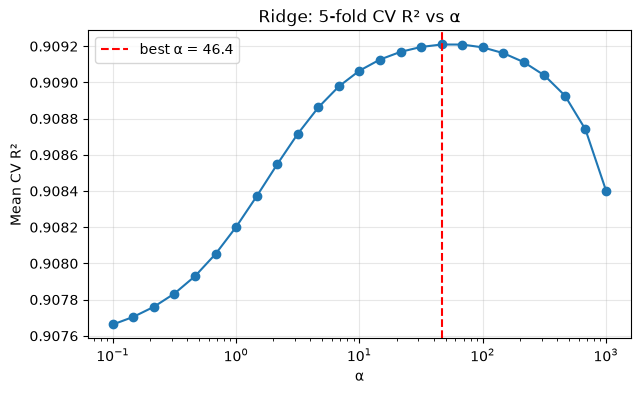

In [81]:
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge

alpha_grid = np.logspace(-1, 3, 25)

# TODO: 5-fold CV over alpha_grid on Xtr_full/ytr_full -> best_alpha
#       then fit Ridge(alpha=best_alpha) on all of Xtr_full and report test R2
#       alongside the unregularized LinearRegression test R2.

''' write your code here '''
kf = KFold(n_splits=5, shuffle=True, random_state=42)
best_alpha = 0
best_alpha_value = -np.inf

alphas_scores = np.zeros(25)
for i,k in enumerate(alpha_grid):
    alphas = i*np.ones(5)
    for j, (train_index, test_index) in enumerate(kf.split(Xtr_full)):
        alphas[j] = Ridge(alpha=k).fit(Xtr_full[train_index], ytr_full[train_index]).score(Xtr_full[test_index], ytr_full[test_index])
    average = alphas.mean()
    alphas_scores[i] = average
    if average > best_alpha_value:
        best_alpha_value = average
        best_alpha = k

best_r2 = Ridge(alpha=best_alpha).fit(Xtr_full, ytr_full).score(Xte_full, yte_full)

print("Ridge R2: ", best_r2)
print("Part C R2:", r2_score(yte_full, pred_full))

plt.figure(figsize=(7, 4))                      
plt.plot(alpha_grid, alphas_scores, marker='o')      
plt.xscale('log')                               
plt.axvline(best_alpha, color='red', linestyle='--', label=f'best α = {best_alpha:.3g}')
plt.xlabel('α')
plt.ylabel('Mean CV R²')
plt.title('Ridge: 5-fold CV R² vs α')
plt.legend()                                   
plt.grid(True, alpha=0.3)                      
plt.show()

### D.2 The same model, with far less data

D.1 measured one training set, at one size. That is a single point on a scale, and it is the end where data is plentiful.

Now vary the size and nothing else, and see what regularization is worth at each.

**Your task.** For each ratio in `ratios` below, take a random training subset of `ratio × p` rows, where `p` is the number of columns, and on that subset:

1. Fit an unregularized `LinearRegression`. Record its R² on the **full test set**, and also on the subset it was trained on — you will need both in D.3.
2. Pick $\alpha$ by 5-fold CV **on that subset** — same procedure as D.1, but over `alpha_grid_small` below rather than D.1's grid. Fit `Ridge` with the winner and record its test R².

The plotting cell below draws the two test-R² curves against each other. Two details that matter:

- **Draw the subset at random** (`np.random.RandomState(seed).choice(...)`) rather than slicing the first *n* rows.
- **Average over the three seeds** at each size. At small sizes a single draw is unstable enough that it can tell you almost anything; three draws show the shape, which is what you are after.


In [82]:
ratios = [2, 3, 5, 10, 25, 50, 100]
seeds  = [100, 101, 102]
alpha_grid_small = np.logspace(-1, 4, 13)   # wider range than D.1, and coarser so the sweep
                                            # doesn't take all afternoon
p = Xtr_full.shape[1]

def cv_best_alpha(X, y, grid):
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    means = []
    for a in grid:
        scores = [Ridge(alpha=a).fit(X[tr], y[tr]).score(X[va], y[va])
                  for tr, va in kf.split(X)]
        means.append(np.mean(scores))
    return grid[int(np.argmax(means))]

# TODO: fill the three lists with one seed-averaged value per ratio, as described above.
plain_r2, plain_train_r2, ridge_r2, sizes = [], [], [], []

for ratio in ratios:
    n = min(ratio * p, Xtr_full.shape[0])
    sizes.append(n)

    ####  PUT YOUR CODE HERE: for each seed, draw a random subset of n rows, fit LinearRegression
    ####  and CV-tuned Ridge on it, and score them on the FULL test set. Append the seed-averaged
    ####  values to plain_r2 (test), plain_train_r2 (train, unregularized) and ridge_r2 (test).
    lr_test, lr_train, rg_test = [], [], []

    for seed in seeds:
        idx = np.random.RandomState(seed).choice(Xtr_full.shape[0], n, replace=False)
        Xs, ys = Xtr_full[idx], ytr_full[idx]

        lr = LinearRegression().fit(Xs, ys)
        lr_test.append(lr.score(Xte_full, yte_full))
        lr_train.append(lr.score(Xs, ys))

        best_a = cv_best_alpha(Xs, ys, alpha_grid_small)
        rg_test.append(Ridge(alpha=best_a).fit(Xs, ys).score(Xte_full, yte_full))

    plain_r2.append(np.mean(lr_test))
    plain_train_r2.append(np.mean(lr_train))
    ridge_r2.append(np.mean(rg_test))


    ###############################################################################################

    print(f'n/p = {ratio:>3}  n = {n:>6}   plain: train R2 = {plain_train_r2[-1]:>7.4f} '
          f'test R2 = {plain_r2[-1]:>8.4f}   |   ridge: test R2 = {ridge_r2[-1]:>7.4f}')


n/p =   2  n =    306   plain: train R2 =  0.9429 test R2 =  -0.5970   |   ridge: test R2 =  0.8637
n/p =   3  n =    459   plain: train R2 =  0.9344 test R2 =   0.8327   |   ridge: test R2 =  0.8698
n/p =   5  n =    765   plain: train R2 =  0.9222 test R2 =   0.8793   |   ridge: test R2 =  0.8882
n/p =  10  n =   1530   plain: train R2 =  0.9148 test R2 =   0.8929   |   ridge: test R2 =  0.8964
n/p =  25  n =   3825   plain: train R2 =  0.9105 test R2 =   0.9023   |   ridge: test R2 =  0.8922
n/p =  50  n =   7650   plain: train R2 =  0.9121 test R2 =   0.9042   |   ridge: test R2 =  0.9040
n/p = 100  n =  15300   plain: train R2 =  0.9106 test R2 =   0.9008   |   ridge: test R2 =  0.9045


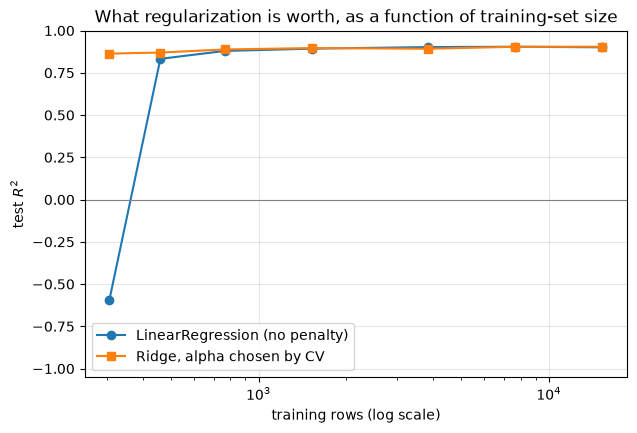

Note: the y-axis is clipped to [-1, 1]; any point outside that range is not drawn.
The printed values above are the source of truth -- read them, not just the picture.


In [83]:
# --- GIVEN, just run this cell once plain_r2 / ridge_r2 are filled ---
plt.figure(figsize=(7, 4.5))
plt.semilogx(sizes, plain_r2, marker='o', label='LinearRegression (no penalty)')
plt.semilogx(sizes, ridge_r2, marker='s', label='Ridge, alpha chosen by CV')
plt.axhline(0, color='grey', linewidth=0.8)
plt.ylim(-1.05, 1.0)
plt.xlabel('training rows (log scale)'); plt.ylabel('test $R^2$')
plt.title('What regularization is worth, as a function of training-set size')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print('Note: the y-axis is clipped to [-1, 1]; any point outside that range is not drawn.')
print('The printed values above are the source of truth -- read them, not just the picture.')


### D.2b The classification counterpart

Same idea, at one size.

**Your task.** On a random subset of `3 * p` rows, drawn with `np.random.RandomState(42)`:

1. Over `C_grid = np.logspace(-3, 2, 11)`, use 5-fold CV on the subset to pick the `C` with the best mean validation ROC-AUC.
2. Report that model's test AUC alongside `LogisticRegression(C=1000, max_iter=5000)`, which is effectively unregularized.

Remember `C` is an *inverse* penalty: small `C` means heavy regularization.


In [84]:
C_grid = np.logspace(-3, 2, 11)
p = Xtr_full.shape[1]

# TODO: 5-fold CV over C_grid on a random 3*p-row subset, then compare test AUC
# against an effectively unregularized C=1000 model.
from sklearn.model_selection import StratifiedKFold

''' write your code here '''
ytr_c = np.asarray(ytr_cls_full)
yte_c = np.asarray(yte_cls_full)

n = 3 * p
idx = np.random.RandomState(42).choice(Xtr_full.shape[0], n, replace=False)
Xs, ys = Xtr_full[idx], ytr_c[idx]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = []
for C in C_grid:
    fold_aucs = []
    for tr, va in skf.split(Xs, ys):
        clf = LogisticRegression(C=C, max_iter=5000).fit(Xs[tr], ys[tr])
        fold_aucs.append(roc_auc_score(ys[va], clf.predict_proba(Xs[va])[:, 1]))
    cv_auc.append(np.mean(fold_aucs))

best_C = C_grid[int(np.argmax(cv_auc))]

tuned = LogisticRegression(C=best_C, max_iter=5000).fit(Xs, ys)
plain = LogisticRegression(C=1000, max_iter=5000).fit(Xs, ys)

tuned_auc = roc_auc_score(yte_c, tuned.predict_proba(Xte_full)[:, 1])
plain_auc = roc_auc_score(yte_c, plain.predict_proba(Xte_full)[:, 1])

print(f'best C = {best_C:.3g}')
print(f'CV-tuned (C = {best_C:.3g}) test AUC: {tuned_auc:.4f}')
print(f'C = 1000 (unregularized) test AUC: {plain_auc:.4f}')

best C = 0.0316
CV-tuned (C = 0.0316) test AUC: 0.9552
C = 1000 (unregularized) test AUC: 0.9346


### D.3 Reflection — answer directly in this cell

1. Describe the plot in D.2 in words. Where do the two curves sit furthest apart, where do they come together, and roughly how much data does it take before the penalty stops earning anything? Then relate your D.1 result to this picture.

  *Your answer:*
  The curves are furthest apart at the smallest subset (n/p = 2, 306 rows): Ridge scores 0.864 test R² while plain LinearRegression scores −0.597, i.e. worse than just predicting the mean. The plain curve jumps to 0.833 at n/p = 3 and meets the Ridge curve around n/p ≈ 5–10 (≈800–1,500 rows). From n/p ≈ 10 onward the two are within ~0.01 of each other, and which one is ahead changes from one size to the next, so the penalty stops adding anything at roughly 10 rows per column. D.1 used the full training set (32,451 rows, n/p ≈ 212), which sits beyond the right edge of this plot, so the near-tie we saw there (0.9052 vs 0.9053) is exactly what this picture predicts.

2. Look at the unregularized model's training R² next to its test R² at the smallest subset, and then at the largest. Explain what a model with that pattern is doing, and how you would recognize the same situation in a problem where you did not already know whether it was overfitting.

  *Your answer:*
  At the smallest subset, train R² is 0.943 but test R² is −0.597, a gap of ~1.5. At the largest it is 0.911 vs 0.901, a gap of ~0.01. With few rows the model is memorizing noise specific to its training rows: it fits them almost perfectly, but its test predictions are worse than predicting the mean. With more data it can no longer memorize, so train R² drops slightly while test R² rises. Without knowing the answer in advance, you recognize overfitting as a large gap between training score and validation/CV score, and as results that swing a lot across different folds or random subsets.

3. Part A's model had 5 parameters and scored badly on test. It is also a bad model, but it fails in the opposite way. Contrast the two failures and say what you would do about each. What would happen if you applied the fix for one to the other?

  *Your answer:*
  Part A's model underfits: with only 5 parameters it is too simple to capture the pattern, so it scores badly on training data as well as test, with little gap between them. The small-subset model in D overfits: high train score, low test score. The fix for underfitting is more flexibility (better features, nonlinear terms, interactions, less penalty). The fix for overfitting is more data or more regularization. Swapping the fixes makes each worse: regularizing the underfit model makes it even simpler and lowers both scores, while adding flexibility to the overfit model at small n widens the train–test gap further.

4. It is tempting to summarize Part D as "overfitting is about the ratio of rows to parameters." That ratio clearly matters here, but it is not the whole story, and question 2 of C.3 already gave you one reason to be careful with the word *parameters*. Give at least two other things that would change how much a model overfits while leaving that ratio untouched.

  *Your answer:*
  Besides counting columns that are actually redundant (rank deficiency, from C.3), other things change overfitting at a fixed rows-to-parameters ratio. One is the noise level in the target: noisier y gives the model more random variation to memorize. Another is how independent the rows are: hourly traffic rows close in time are highly correlated, so n rows carry less information than n independent samples. A third is collinearity between features, which makes coefficients unstable even when the columns are not exactly redundant. Regularization strength also matters: Ridge at n/p = 2 still reached 0.864 test R², at the same ratio where plain regression collapsed to −0.597.

5. Your D.1 cross-validation took real compute and may well have changed nothing. Was running it a waste of time? Answer in terms of what you would have had to assume if you had skipped it.

  *Your answer:*
  No. Skipping it would have meant assuming, without evidence, that regularization doesn't matter at this data size, or picking α arbitrarily, or picking it on the test set (leakage). D.2 shows the same procedure matters enormously at small n, and you cannot tell in advance which regime you are in. The result "CV changed nothing" is itself the evidence that the penalty isn't needed here, rather than an assumption.